# Prédiction du diabète avec Spark (BRFSS 2013–2015)
**Le notebook s'exécute-t-il de bout en bout ?**
Oui, sur Kaggle, après les corrections ci-dessous.

**Problèmes rencontrés :**
- Sur Kaggle, le jeu de données n'était pas attaché au notebook, donc aucun fichier n'était trouvé (`reduce() of empty iterable`).
- En lisant plusieurs CSV d'un coup, Spark applique l'en-tête du premier fichier à tous les autres, alors que l'ordre des colonnes change selon les années.
- Les colonnes tension (`_RFHYPE5`) et cholestérol (`TOLDHI2`) sont absentes en 2014 : ces questions ne sont posées que les années impaires.

**Modifications apportées :**
- Recherche automatique des fichiers, avec un message clair si les données manquent.
- Lecture de chaque année séparément, puis fusion par nom de colonne (`unionByName`).
- Utilisation des années 2013 (entraînement, 359 552 personnes) et 2015 (test, 313 466 personnes), avec une pondération des diabétiques, minoritaires.



**Données :** [BRFSS – Kaggle](https://www.kaggle.com/datasets/cdc/behavioral-risk-factor-surveillance-system), enquêtes de santé du CDC (environ 400 000 personnes par an).

**Objectif :** prédire si une personne est diabétique à partir de son âge, de son IMC, de sa tension, de son cholestérol et de son mode de vie.


In [1]:
!pip install -q pyspark

import glob, os
from functools import reduce
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

spark = SparkSession.builder.master("local[*]").config("spark.driver.memory", "8g").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/12 15:43:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Data

Chaque année est lue séparément (l'ordre des colonnes change d'un fichier à l'autre), puis réunie par nom de colonne. Codes utilisés : DIABETE3 (1 = diabète, 3 = non), _AGEG5YR (tranche d'âge 1 à 13), SEX (2 = femme), _BMI5 (IMC × 100), _RFHYPE5 (2 = tension élevée), TOLDHI2 (1 = cholestérol), SMOKE100 (1 = fumeur), EXERANY2 (1 = sport), GENHLTH (santé 1 à 5). Les codes 7, 9 et 14 = « ne sait pas / refus ».

In [5]:
COLONNES = ["DIABETE3", "_AGEG5YR", "SEX", "_BMI5", "_RFHYPE5", "TOLDHI2", "SMOKE100", "EXERANY2", "GENHLTH"]
ANNEES = ["2013", "2015"]  

tous = glob.glob("/kaggle/input/**/*.csv", recursive=True)
fichiers = sorted(f for f in tous if any(a in os.path.basename(f) for a in ANNEES))
print("Fichiers utilisés :", fichiers)

morceaux = []
for f in fichiers:
    t = spark.read.csv(f, header=True)
    annee = int([a for a in ANNEES if a in os.path.basename(f)][0])
    print(annee, ": colonnes absentes :", [c for c in COLONNES if c not in t.columns])
    t = t.select(*[(F.col(c) if c in t.columns else F.lit(None)).cast("double").alias(c) for c in COLONNES])
    morceaux.append(t.withColumn("ANNEE", F.lit(annee)))

df = reduce(lambda a, b: a.unionByName(b), morceaux).cache()
print("Lignes :", df.count())
df.show(5)

Fichiers utilisés : ['/kaggle/input/datasets/cdc/behavioral-risk-factor-surveillance-system/2013.csv', '/kaggle/input/datasets/cdc/behavioral-risk-factor-surveillance-system/2015.csv']
2013 : colonnes absentes : []
2015 : colonnes absentes : []
Lignes : 933229
+--------+--------+---+------+--------+-------+--------+--------+-------+-----+
|DIABETE3|_AGEG5YR|SEX| _BMI5|_RFHYPE5|TOLDHI2|SMOKE100|EXERANY2|GENHLTH|ANNEE|
+--------+--------+---+------+--------+-------+--------+--------+-------+-----+
|     3.0|     9.0|2.0|3916.0|     2.0|    1.0|     1.0|     2.0|    4.0| 2013|
|     3.0|     7.0|2.0|1822.0|     1.0|    2.0|     2.0|     1.0|    3.0| 2013|
|     3.0|     8.0|2.0|2746.0|     1.0|    2.0|     1.0|     2.0|    3.0| 2013|
|     3.0|     9.0|2.0|2197.0|     1.0|    1.0|     2.0|     1.0|    2.0| 2013|
|     3.0|    10.0|1.0|3594.0|     2.0|    2.0|     1.0|     2.0|    3.0| 2013|
+--------+--------+---+------+--------+-------+--------+--------+-------+-----+
only showing top 5 

## 2. EDA

Spark calcule les statistiques sur toutes les données ; on ne convertit en pandas (toPandas) que le petit résultat, pour tracer le graphique.

Taux de diabète : 13.2 %


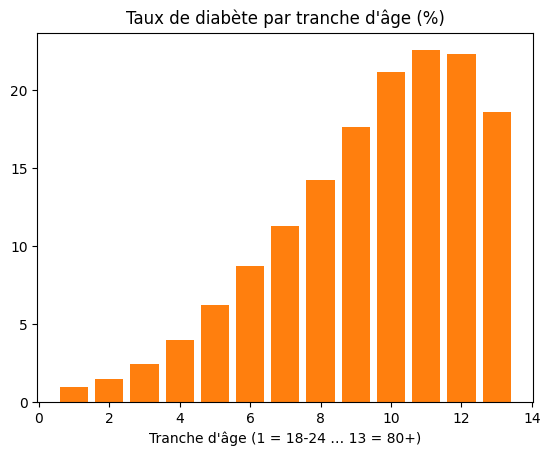

In [6]:
diab = df.filter(F.col("DIABETE3").isin(1, 3)).withColumn("DIABETE", (F.col("DIABETE3") == 1).cast("int"))
print("Taux de diabète :", round(diab.agg(F.avg("DIABETE")).first()[0] * 100, 1), "%")

par_age = (diab.filter("_AGEG5YR <= 13").groupBy("_AGEG5YR").agg(F.avg("DIABETE").alias("taux"))
           .orderBy("_AGEG5YR").toPandas())
plt.bar(par_age["_AGEG5YR"], par_age["taux"] * 100, color="tab:orange")
plt.title("Taux de diabète par tranche d'âge (%)")
plt.xlabel("Tranche d'âge (1 = 18-24 … 13 = 80+)")
plt.show()

## 3. Prétraitement et 4. Transformation

- On supprime les réponses « ne sait pas / refus » et les valeurs manquantes.
- On recode les réponses en **1/0** et l'IMC en vraie valeur (÷ 100).
- VectorAssembler (étape suivante) regroupe les variables dans une seule colonne features, le format attendu par Spark.
- **Découpage temporel :** on entraîne sur **2013** et on teste sur **2015**, comme si on prédisait une année future.

In [7]:
donnees = (diab.dropna()
           .filter("_AGEG5YR <= 13 AND _RFHYPE5 IN (1, 2) AND TOLDHI2 IN (1, 2) "
                   "AND SMOKE100 IN (1, 2) AND EXERANY2 IN (1, 2) AND GENHLTH <= 5")
           .select("ANNEE", "DIABETE",
                   F.col("_AGEG5YR").alias("AGE"),
                   (F.col("SEX") == 2).cast("int").alias("FEMME"),
                   (F.col("_BMI5") / 100).alias("IMC"),
                   (F.col("_RFHYPE5") == 2).cast("int").alias("TENSION"),
                   (F.col("TOLDHI2") == 1).cast("int").alias("CHOLESTEROL"),
                   (F.col("SMOKE100") == 1).cast("int").alias("FUMEUR"),
                   (F.col("EXERANY2") == 1).cast("int").alias("SPORT"),
                   F.col("GENHLTH").alias("SANTE")))

VARIABLES = ["AGE", "FEMME", "IMC", "TENSION", "CHOLESTEROL", "FUMEUR", "SPORT", "SANTE"]
train = donnees.filter("ANNEE = 2013")
test = donnees.filter("ANNEE = 2015")
print("Entraînement (2013) :", train.count(), "| Test (2015) :", test.count())

Entraînement (2013) : 359552 | Test (2015) : 313466


## 5. ML

Régression logistique de **Spark MLlib**, entraînée sur toutes les données de 2013. La colonne POIDS donne plus d'importance aux diabétiques, minoritaires (équivalent de class_weight="balanced" dans scikit-learn).

In [8]:
taux = train.agg(F.avg("DIABETE")).first()[0]
train = train.withColumn("POIDS", F.when(F.col("DIABETE") == 1, 1 - taux).otherwise(taux))

pipeline = Pipeline(stages=[
    VectorAssembler(inputCols=VARIABLES, outputCol="features"),
    LogisticRegression(labelCol="DIABETE", weightCol="POIDS"),
])
modele = pipeline.fit(train)
print("Modèle entraîné.")

Modèle entraîné.


## 6. Évaluation

- **AUC** : capacité à classer un diabétique au-dessus d'un non-diabétique (0,5 = hasard, 1 = parfait).
- **Rappel** : parmi les diabétiques, combien le modèle en a repéré.
- Le tableau final est la **matrice de confusion** (réel × prédit).

In [9]:
pred = modele.transform(test)
auc = BinaryClassificationEvaluator(labelCol="DIABETE").evaluate(pred)
rappel = pred.filter("DIABETE = 1 AND prediction = 1").count() / pred.filter("DIABETE = 1").count()

print("AUC    :", round(auc, 3))
print("Rappel :", round(rappel, 3))
pred.groupBy("DIABETE", "prediction").count().orderBy("DIABETE", "prediction").show()

AUC    : 0.816
Rappel : 0.762


+-------+----------+------+
|DIABETE|prediction| count|
+-------+----------+------+
|      0|       0.0|191770|
|      0|       1.0| 75016|
|      1|       0.0| 11099|
|      1|       1.0| 35581|
+-------+----------+------+



## 7. Déploiement

On sauvegarde le pipeline complet (assemblage + modèle), on le recharge, puis on prédit le risque pour une nouvelle personne.

In [10]:
modele.write().overwrite().save("modele_diabete")
modele = PipelineModel.load("modele_diabete")

# Ordre : AGE, FEMME, IMC, TENSION, CHOLESTEROL, FUMEUR, SPORT, SANTE
personne = spark.createDataFrame([(10, 0, 35.0, 1, 1, 1, 0, 4.0)], VARIABLES)   # homme de 65-69 ans, IMC 35…
proba = modele.transform(personne).first()["probability"][1]
print(f"Risque de diabète : {proba:.0%}")

Risque de diabète : 89%


## Conclusion

Spark a permis de réaliser les 7 étapes sur **toutes les données** de deux années d'enquête (2013 et 2015), sans les charger en mémoire avec pandas.

**Limites :**
- les questions sur la tension et le cholestérol ne sont posées qu'une année sur deux, ce qui limite les années utilisables ;
- Spark tourne ici sur une seule machine (mode local), mais le même code fonctionnerait sur un cluster pour des volumes beaucoup plus grands.